# PhishGuard — ML Training
Run all cells top to bottom (Kernel → Restart & Run All). All numbers come from real execution; no outputs are pre-filled.

## 01 Import dataset
Edit `config.py` to change the dataset path / column names. Labels: 0 = legitimate, 1 = phishing.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..')); os.chdir('..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import config
from src.preprocessing import load_dataset, build_matrix
df = load_dataset()
df.head()

,url,label
0,https://www.microsoft.com?id=973,0
1,https://www.microsoft.com/blog/2024/05/post?id...,0
2,https://www.who.int/wiki/Machine_learning?id=234,0
3,http://docs.python.org/,0
4,https://github.com/wiki/Machine_learning,0


## 02 Dataset cleaning
`load_dataset` drops missing rows and **duplicate URLs** (prevents the same URL landing in both train and test).

In [2]:
print(df.shape); print(df['label'].value_counts()); df.isna().sum()

(600, 2)
label
0    300
1    300
Name: count, dtype: int64


url      0
label    0
dtype: int64

## 03 Exploratory data analysis

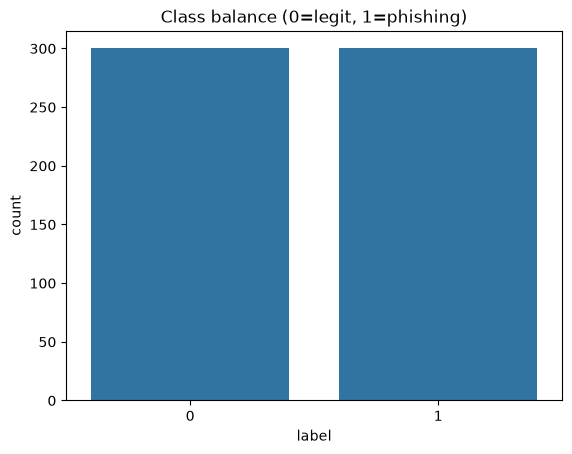

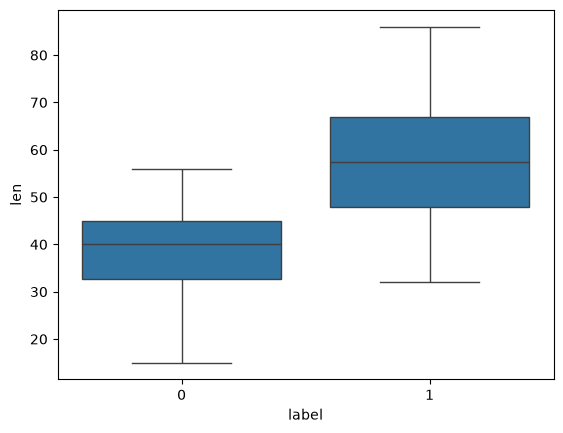

In [3]:
sns.countplot(x='label', data=df); plt.title('Class balance (0=legit, 1=phishing)'); plt.show()
df['len']=df.url.str.len(); sns.boxplot(x='label', y='len', data=df); plt.show()

## 04 Feature extraction
The **same** `extract_features` used by the Flask app produces the training matrix, guaranteeing identical feature definitions and order.

In [4]:
X, y = build_matrix(df)
print(X.shape); X.head()

(600, 30)


,url_length,hostname_length,path_length,query_length,fragment_length,num_dots,num_slashes,num_hyphens,num_underscores,num_digits,...,entropy,is_https,suspicious_tld,domain_length,domain_has_digits,domain_hyphens,keyword_count,is_shortener,nonstandard_port,digit_ratio
0,32,17,0,6,0,2,2,0,0,3,...,4.1792,1,0,9,0,0,0,0,0,0.0938
1,50,17,18,6,0,2,6,0,0,9,...,4.4313,1,0,9,0,0,0,0,0,0.1800
2,48,11,22,6,0,2,4,0,1,3,...,4.3635,1,0,3,0,0,0,0,0,0.0625
3,23,15,1,0,0,2,3,0,0,0,...,3.6425,0,0,6,0,0,0,0,0,0.0000
4,40,10,22,0,0,1,4,0,1,0,...,4.2751,1,0,6,0,0,0,0,0,0.0000


## 05 Feature distribution

In [5]:
X.assign(label=y).groupby('label')[['url_length','num_subdomains','keyword_count','is_https','suspicious_tld','is_ip_host','entropy']].mean().T

label,0,1
url_length,38.356667,57.586667
num_subdomains,0.763333,0.740000
keyword_count,0.000000,1.920000
is_https,0.650000,0.340000
suspicious_tld,0.000000,0.623333
is_ip_host,0.000000,0.253333
entropy,4.176110,4.323558


## 06 Train/test split & data-leakage prevention
* Stratified 80/20 split, fixed seed.
* URLs de-duplicated beforehand; the label is never a feature; the split happens **before** fitting; medians for explanations use training data only.
* All reported metrics use only the unseen test set.

In [6]:
from src.model_utils import split_data
Xtr, Xte, ytr, yte = split_data(X, y)
print(len(Xtr), len(Xte), set(df.url[:0]))

480 120 set()


## 07 Model training

In [7]:
from src.model_utils import get_models, evaluate
models = get_models()
for n, m in models.items(): m.fit(Xtr, ytr)
list(models)

['Logistic Regression', 'Decision Tree', 'Random Forest']

## 08 Model comparison
False negatives (phishing labelled legitimate) are the costliest error in security, so watch **recall/FNR**, not just accuracy.

In [8]:
res = {n: evaluate(m, Xte, yte) for n, m in models.items()}
cmp = pd.DataFrame(res).T.drop(columns='confusion_matrix'); cmp.round(4)

,accuracy,precision,recall,f1,roc_auc,fpr,fnr
Logistic Regression,1.0,1.0,1.0,1.0,1.0,0.0,0.0
Decision Tree,1.0,1.0,1.0,1.0,1.0,0.0,0.0
Random Forest,1.0,1.0,1.0,1.0,1.0,0.0,0.0


## 09 Hyperparameter tuning (Random Forest)

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
gs = GridSearchCV(RandomForestClassifier(random_state=42), {'n_estimators':[100,200],'max_depth':[None,10,20]}, cv=5, scoring='f1', n_jobs=-1)
gs.fit(Xtr, ytr); print(gs.best_params_, gs.best_score_)

{'max_depth': None, 'n_estimators': 100} 1.0


## 10 Model evaluation (tuned RF, unseen test data)

{'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'roc_auc': 1.0, 'fpr': np.float64(0.0), 'fnr': np.float64(0.0), 'confusion_matrix': [[60, 0], [0, 60]]}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       1.00      1.00      1.00        60

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120



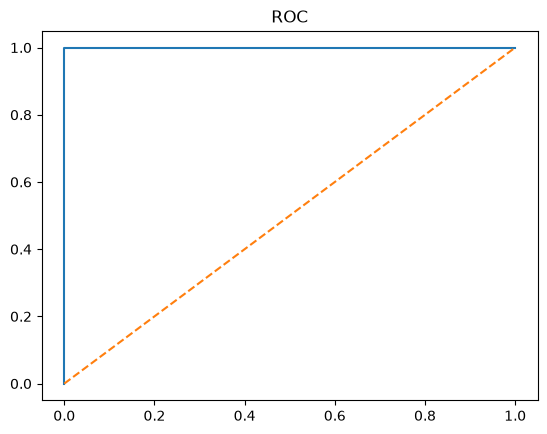

In [10]:
from sklearn.metrics import classification_report, roc_curve
best_rf = gs.best_estimator_; print(evaluate(best_rf, Xte, yte)); print(classification_report(yte, best_rf.predict(Xte)))
fpr,tpr,_ = roc_curve(yte, best_rf.predict_proba(Xte)[:,1]); plt.plot(fpr,tpr); plt.plot([0,1],[0,1],'--'); plt.title('ROC'); plt.show()

## 11 Feature importance (computed, not invented)

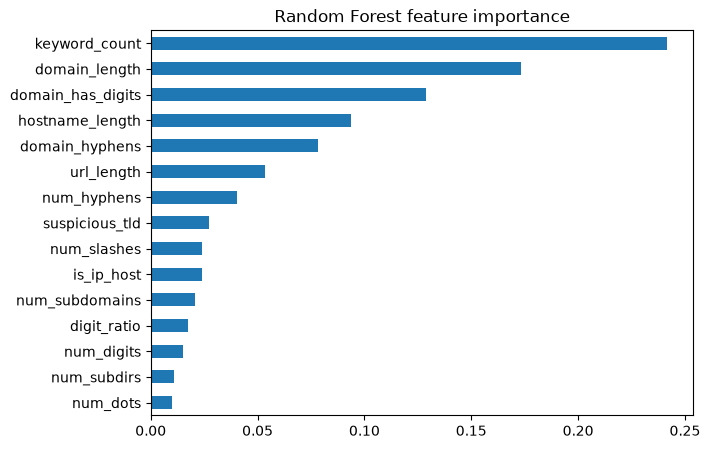

In [11]:
imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()
imp.tail(15).plot.barh(figsize=(7,5), title='Random Forest feature importance'); plt.show()

## 12 Confusion matrix

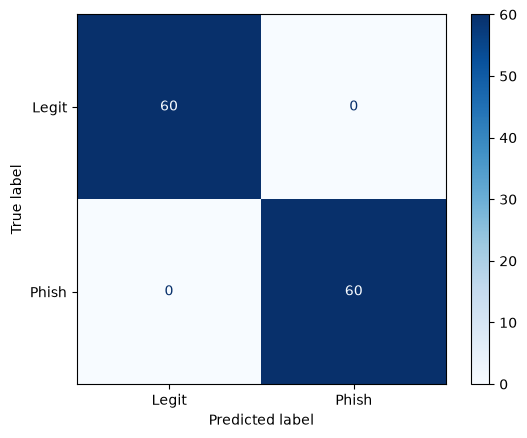

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best_rf, Xte, yte, display_labels=['Legit','Phish'], cmap='Blues'); plt.show()

## 13 Save model
Saves the bundle (model + feature list + training medians) and `metrics.json` to `models/`, which the Flask app loads.

In [13]:
from src.model_utils import train_and_save
results, best, importance = train_and_save(); print('Saved best model:', best)

Saved best model: Random Forest


## 14 Test custom URLs

In [14]:
from src.prediction import analyze_url
for u in ['https://www.wikipedia.org/','http://192.168.4.7/login/verify','http://secure-login-paypal-verify.xyz/account']:
    r = analyze_url(u); print(u, '->', r['verdict'], r['score'], r['prob'])

https://www.wikipedia.org/ -> LIKELY LEGITIMATE 0 0.0
http://192.168.4.7/login/verify -> LIKELY PHISHING 85 99.0
http://secure-login-paypal-verify.xyz/account -> LIKELY PHISHING 74 82.5
